# Email classification

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import html
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.preprocessing import LabelEncoder

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
dataset01 = '/content/drive/MyDrive/VC11/'

In [10]:
df = pd.read_csv("/content/drive/MyDrive/VC11/email_classification_dataset.csv")

In [11]:
df

,mail_subject,mail_body,label
0,Craving something new? Lumen Energy Co. has yo...,"Hi Stephen,\n\nWe have put together a selectio...",ADVERTISEMENT
1,We stopped a suspicious login attempt,"Hi Melissa,\n\nThis code will expire in 10 min...",SECURITY
2,A note about your coverage,"Dear James,\n\nYour recent lab results are now...",HEALTHCARE
3,What's happening in your community,"Hi Lucia,\n\nThank you for your continued inte...",OTHER
4,A moment worth marking together,"Greetings Sofia,\n\nFeel free to bring a plus ...",INVITATION
...,...,...,...
119995,Here's how things look this month,"Greetings George,\n\nThe team meeting is sched...",WORK
119996,"A small gift, just for you","Hi Pamela,\n\nFor a limited time, save 50% on ...",ADVERTISEMENT
119997,Changes to your streaming plan,"Hi Mary,\n\nThere has been an update to your S...",SUBSCRIPTIONS
119998,Scholarship opportunity available,"Dear Linda,\n\nThe exam will be held on Novemb...",EDUCATION


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   mail_subject  120000 non-null  object
 1   mail_body     120000 non-null  object
 2   label         120000 non-null  object
dtypes: object(3)
memory usage: 2.7+ MB


In [13]:
df.describe(include="all")

,mail_subject,mail_body,label
count,120000,120000,120000
unique,7748,119994,20
top,Update on your application,"Hi Eric,\n\nLog in to see the full update. You...",ADVERTISEMENT
freq,988,2,6000


In [15]:
print("Before duplicates:", len(df))

df = df.drop_duplicates(
    subset=["mail_subject", "mail_body"]
)

print("After duplicates:", len(df))

Before duplicates: 120000
After duplicates: 120000


In [17]:
df["text"] = (
    "SUBJECT: " + df["mail_subject"] +
    " BODY: " + df["mail_body"]
)

In [18]:
df[["mail_subject", "mail_body", "label", "text"]].head()

,mail_subject,mail_body,label,text
0,Craving something new? Lumen Energy Co. has yo...,"Hi Stephen,\n\nWe have put together a selectio...",ADVERTISEMENT,SUBJECT: Craving something new? Lumen Energy C...
1,We stopped a suspicious login attempt,"Hi Melissa,\n\nThis code will expire in 10 min...",SECURITY,SUBJECT: We stopped a suspicious login attempt...
2,A note about your coverage,"Dear James,\n\nYour recent lab results are now...",HEALTHCARE,SUBJECT: A note about your coverage BODY: Dear...
3,What's happening in your community,"Hi Lucia,\n\nThank you for your continued inte...",OTHER,SUBJECT: What's happening in your community BO...
4,A moment worth marking together,"Greetings Sofia,\n\nFeel free to bring a plus ...",INVITATION,SUBJECT: A moment worth marking together BODY:...


In [19]:
def clean_text(text):
    text = str(text)

    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Remove email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        " ",
        text
    )

    # Keep alphanumeric characters
    text = re.sub(
        r"[^a-zA-Z0-9\s]",
        " ",
        text
    )

    # Convert to lowercase
    text = text.lower()

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

In [20]:
df["clean_text"] = df["text"].apply(clean_text)

In [21]:
df[["text", "clean_text"]].head()

,text,clean_text
0,SUBJECT: Craving something new? Lumen Energy C...,subject craving something new lumen energy co ...
1,SUBJECT: We stopped a suspicious login attempt...,subject we stopped a suspicious login attempt ...
2,SUBJECT: A note about your coverage BODY: Dear...,subject a note about your coverage body dear j...
3,SUBJECT: What's happening in your community BO...,subject what s happening in your community bod...
4,SUBJECT: A moment worth marking together BODY:...,subject a moment worth marking together body g...


In [22]:
df = df[
    df["clean_text"].str.strip().str.len() > 0
].copy()

In [23]:
print(df["label"].value_counts())

label
ADVERTISEMENT            6000
SECURITY                 6000
HEALTHCARE               6000
OTHER                    6000
INVITATION               6000
NEWSLETTER               6000
EDUCATION                6000
SPAM                     6000
SUBSCRIPTIONS            6000
WORK                     6000
GOVERNMENT               6000
SOCIAL                   6000
PERSONAL                 6000
JOBS                     6000
SHOPPING                 6000
FINANCE                  6000
UPDATES_NOTIFICATIONS    6000
CUSTOMER_SUPPORT         6000
TRAVEL                   6000
BILLS_UTILITIES          6000
Name: count, dtype: int64


In [24]:
class_percentage = (
    df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(class_percentage)

label
ADVERTISEMENT            5.0
SECURITY                 5.0
HEALTHCARE               5.0
OTHER                    5.0
INVITATION               5.0
NEWSLETTER               5.0
EDUCATION                5.0
SPAM                     5.0
SUBSCRIPTIONS            5.0
WORK                     5.0
GOVERNMENT               5.0
SOCIAL                   5.0
PERSONAL                 5.0
JOBS                     5.0
SHOPPING                 5.0
FINANCE                  5.0
UPDATES_NOTIFICATIONS    5.0
CUSTOMER_SUPPORT         5.0
TRAVEL                   5.0
BILLS_UTILITIES          5.0
Name: proportion, dtype: float64


In [25]:
label_encoder = LabelEncoder()

df["label_encoded"] = label_encoder.fit_transform(
    df["label"]
)

In [26]:
label_mapping = dict(
    zip(
        label_encoder.classes_,
        range(len(label_encoder.classes_))
    )
)

print(label_mapping)

{'ADVERTISEMENT': 0, 'BILLS_UTILITIES': 1, 'CUSTOMER_SUPPORT': 2, 'EDUCATION': 3, 'FINANCE': 4, 'GOVERNMENT': 5, 'HEALTHCARE': 6, 'INVITATION': 7, 'JOBS': 8, 'NEWSLETTER': 9, 'OTHER': 10, 'PERSONAL': 11, 'SECURITY': 12, 'SHOPPING': 13, 'SOCIAL': 14, 'SPAM': 15, 'SUBSCRIPTIONS': 16, 'TRAVEL': 17, 'UPDATES_NOTIFICATIONS': 18, 'WORK': 19}


In [27]:
X = df["clean_text"]
y = df["label_encoded"]

In [31]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [29]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    max_features=200000
)

In [32]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

In [33]:
print(
    "Training TF-IDF shape:",
    X_train_tfidf.shape
)

print(
    "Validation TF-IDF shape:",
    X_val_tfidf.shape
)

print(
    "Test TF-IDF shape:",
    X_test_tfidf.shape
)

Training TF-IDF shape: (84000, 53289)
Validation TF-IDF shape: (18000, 53289)
Test TF-IDF shape: (18000, 53289)


In [34]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    C=2.0,
    solver="liblinear"
)

In [36]:
model.fit(
    X_train_tfidf,
    y_train
)

LogisticRegression(C=2.0, class_weight='balanced', max_iter=1000,
                   solver='liblinear')

In [37]:
y_val_pred = model.predict(
    X_val_tfidf
)

In [38]:
val_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

print(
    f"Validation Accuracy: {val_accuracy:.4f}"
)

Validation Accuracy: 1.0000


In [39]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=label_encoder.classes_
    )
)

                       precision    recall  f1-score   support

        ADVERTISEMENT       1.00      1.00      1.00       900
      BILLS_UTILITIES       1.00      1.00      1.00       900
     CUSTOMER_SUPPORT       1.00      1.00      1.00       900
            EDUCATION       1.00      1.00      1.00       900
              FINANCE       1.00      1.00      1.00       900
           GOVERNMENT       1.00      1.00      1.00       900
           HEALTHCARE       1.00      1.00      1.00       900
           INVITATION       1.00      1.00      1.00       900
                 JOBS       1.00      1.00      1.00       900
           NEWSLETTER       1.00      1.00      1.00       900
                OTHER       1.00      1.00      1.00       900
             PERSONAL       1.00      1.00      1.00       900
             SECURITY       1.00      1.00      1.00       900
             SHOPPING       1.00      1.00      1.00       900
               SOCIAL       1.00      1.00      1.00  

In [40]:
cm = confusion_matrix(
    y_val,
    y_val_pred
)

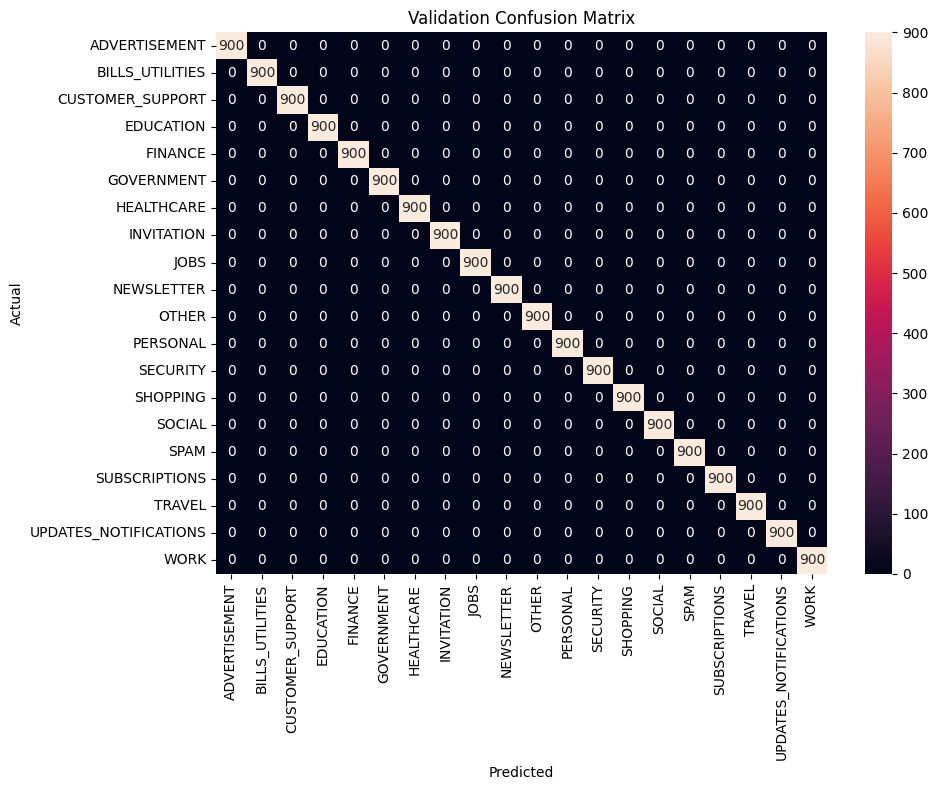

In [41]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Validation Confusion Matrix")

plt.tight_layout()
plt.show()

In [42]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced"
)

svm_model.fit(
    X_train_tfidf,
    y_train
)

LinearSVC(class_weight='balanced')

In [43]:
cross_val_accuracy = accuracy_score(
    y_val,
    svm_model.predict(X_val_tfidf)
)

In [44]:
cross_val_accuracy = accuracy_score(
    y_val,
    model.predict(X_val_tfidf))

In [45]:
cross_val_accuracy

1.0

In [49]:
from sklearn.model_selection import cross_val_score


logistic_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        max_features=200000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        C=2.0,
        solver="liblinear"
    ))
])

svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        max_features=200000
    )),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced"
    ))
])

logistic_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

svm_scores = cross_val_score(
    svm_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print(f"Logistic Regression CV accuracy: {logistic_scores.mean():.4f} +/- {logistic_scores.std():.4f}")
print(f"LinearSVC CV accuracy: {svm_scores.mean():.4f} +/- {svm_scores.std():.4f}")

Logistic Regression CV accuracy: 1.0000 +/- 0.0000
LinearSVC CV accuracy: 1.0000 +/- 0.0000


In [50]:
from sklearn.metrics import accuracy_score, classification_report

logistic_pipeline.fit(X_train, y_train)
svm_pipeline.fit(X_train, y_train)

logistic_test_pred = logistic_pipeline.predict(X_test)
svm_test_pred = svm_pipeline.predict(X_test)

print("Logistic Regression test accuracy:")
print(accuracy_score(y_test, logistic_test_pred))
print(classification_report(
    y_test,
    logistic_test_pred,
    target_names=label_encoder.classes_
))

print("LinearSVC test accuracy:")
print(accuracy_score(y_test, svm_test_pred))
print(classification_report(
    y_test,
    svm_test_pred,
    target_names=label_encoder.classes_
))

Logistic Regression test accuracy:
1.0
                       precision    recall  f1-score   support

        ADVERTISEMENT       1.00      1.00      1.00       900
      BILLS_UTILITIES       1.00      1.00      1.00       900
     CUSTOMER_SUPPORT       1.00      1.00      1.00       900
            EDUCATION       1.00      1.00      1.00       900
              FINANCE       1.00      1.00      1.00       900
           GOVERNMENT       1.00      1.00      1.00       900
           HEALTHCARE       1.00      1.00      1.00       900
           INVITATION       1.00      1.00      1.00       900
                 JOBS       1.00      1.00      1.00       900
           NEWSLETTER       1.00      1.00      1.00       900
                OTHER       1.00      1.00      1.00       900
             PERSONAL       1.00      1.00      1.00       900
             SECURITY       1.00      1.00      1.00       900
             SHOPPING       1.00      1.00      1.00       900
               

In [51]:
import os

artifact_dir = "/content/drive/MyDrive/VC11/models"
os.makedirs(artifact_dir, exist_ok=True)

tfidf_config = {
    "lowercase": True,
    "stop_words": "english",
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 0.95,
    "sublinear_tf": True,
    "max_features": 200000
}

logistic_artifact = {
    "pipeline": logistic_pipeline,
    "label_encoder": label_encoder,
    "tfidf_config": tfidf_config,
    "input_column": "clean_text",
}

svm_artifact = {
    "pipeline": svm_pipeline,
    "label_encoder": label_encoder,
    "tfidf_config": tfidf_config,
    "input_column": "clean_text",
}

logistic_path = os.path.join(
    artifact_dir,
    "logistic_regression_email_pipeline.pkl"
)
svm_path = os.path.join(
    artifact_dir,
    "linear_svc_email_pipeline.pkl"
)

joblib.dump(logistic_artifact, logistic_path)
joblib.dump(svm_artifact, svm_path)

print(f"Saved Logistic Regression artifact: {logistic_path}")
print(f"Saved LinearSVC artifact: {svm_path}")

Saved Logistic Regression artifact: /content/drive/MyDrive/VC11/models/logistic_regression_email_pipeline.pkl
Saved LinearSVC artifact: /content/drive/MyDrive/VC11/models/linear_svc_email_pipeline.pkl


In [54]:
subject = "Rohit Jadhav Internship opening at Skillbit Technologies"

mail_body = """
Internship at
Skillbit⁠‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌
‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌ ‌
[/https://newsletter.uptricks.com/b/c/v2gxpL-VQ7xXk9-1cO4dD]
Is this email not displaying correctly? View it in your browser.
[/https://newsletter.uptricks.com/browser_preview/v2gxpL-VQ7xXk9-1cO4dD]
DEAR ,
﻿
Please find the below details about Internship opening at Skillbit
Technologies.
Internship Details:
*
DURATION: 2 Months
*
LAST DATE TO REGISTER: 11th July 2026
*
INTERNSHIP STARTING DATE: 13th July 2026
*
ELIGIBILITY: Any Student who are willing to learn new things
*
LOCATION: Work from Home
*
PERKS: Offer letter & Completion Certificate
INTERNSHIP DOMAINS:
*
C Programming
*
C++ Programming
*
Java
*
Data Science
*
Machine Learning
*
Python
*
Full-Stack Development
*
Web Development
*
Front-End Development
*
AWS Cloud
*
Android
*
Data Analytics
*
Artificial Intelligence
REGISTRATION LINK: CLICK HERE
[https://newsletter.uptricks.com/link_click/v2gxpL-VQ7xXk9-1cO4dD/19b52dc3d2e28d20c607c336c75ae9ba]
THANKS
SKILLBIT TECHNOLOGIES
If you would like to unsubscribe, please click here.
[/https://newsletter.uptricks.com/unsubscribe/v2gxpL-VQ7xXk9-1cO4dD]
[Powered by Sender.net]
[https://sender.net?utm_source=sender_user&utm_campaign=187144]
"""

mail_text = clean_text(
    "SUBJECT: " + subject + " BODY: " + mail_body
)

loaded_logistic_artifact = joblib.load(logistic_path)
loaded_svm_artifact = joblib.load(svm_path)

loaded_logistic_pipeline = loaded_logistic_artifact["pipeline"]
loaded_svm_pipeline = loaded_svm_artifact["pipeline"]
loaded_label_encoder = loaded_logistic_artifact["label_encoder"]

logistic_prediction = loaded_logistic_pipeline.predict([mail_text])[0]
svm_prediction = loaded_svm_pipeline.predict([mail_text])[0]

logistic_label = loaded_label_encoder.inverse_transform([logistic_prediction])[0]
svm_label = loaded_label_encoder.inverse_transform([svm_prediction])[0]

print("Logistic Regression label:", logistic_label)
print("LinearSVC label:", svm_label)

if hasattr(loaded_logistic_pipeline, "predict_proba"):
    logistic_confidence = loaded_logistic_pipeline.predict_proba([mail_text]).max()
    print(f"Logistic Regression confidence: {logistic_confidence:.4f}")

svm_decision = loaded_svm_pipeline.decision_function([mail_text])
print("LinearSVC decision scores:", svm_decision)

Logistic Regression label: SPAM
LinearSVC label: SPAM
Logistic Regression confidence: 0.3466
LinearSVC decision scores: [[-0.81986879 -1.04433366 -0.98641277 -0.80616021 -0.86306149 -1.03267152
  -1.02933055 -0.94612631 -0.93481775 -0.93185638 -0.97747892 -1.13789647
  -0.89927799 -0.90900474 -0.95882721 -0.62325759 -0.91036886 -0.94643067
  -0.79531817 -0.98442689]]
